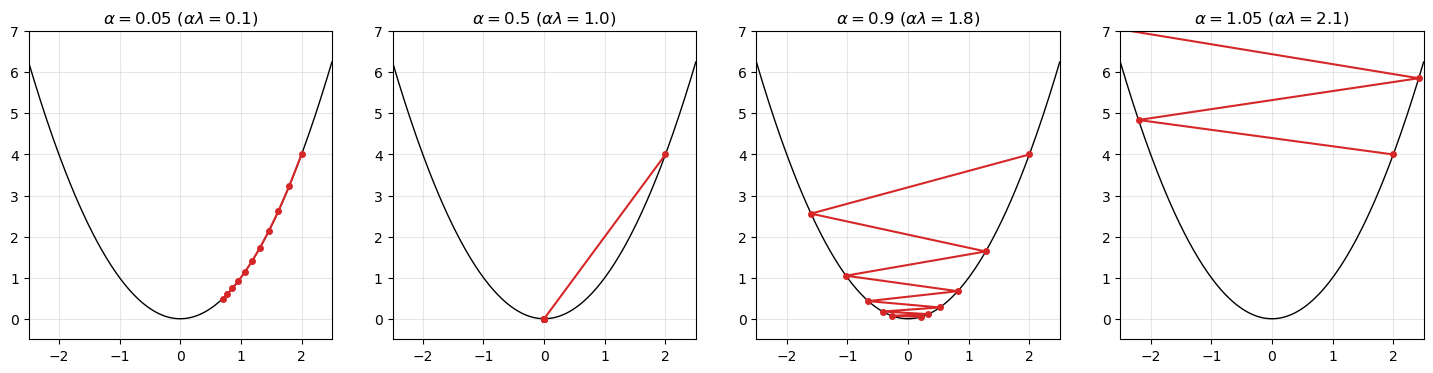

In [1]:
import numpy as np
import matplotlib.pyplot as plt

lam = 2.0
f = lambda x: 0.5 * lam * x**2
df = lambda x: lam * x

xx = np.linspace(-2.5, 2.5, 200)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, alpha in zip(axes, [0.05, 0.5, 0.9, 1.05]):
    x = 2.0
    xs = [x]
    for k in range(10):
        x = x - alpha * df(x)
        xs.append(x)
    xs = np.array(xs)

    ax.plot(xx, f(xx), 'k', lw=1)
    ax.plot(xs, f(xs), 'o-', color="tab:red", ms=4)
    ax.set_title(rf"$\alpha = {alpha}$ ($\alpha\lambda = {alpha * lam:.1f}$)")
    ax.set_ylim(-0.5, 7)
    ax.set_xlim(-2.5, 2.5)
    ax.grid(alpha=0.3)
plt.show()

In [2]:
def backtracking(f, grad_f, x, alpha0=1.0, tau=0.5, c=1e-4):
    """
    Returns a step size alpha that satisfies the Armijo condition:
        f(x - alpha * g) <= f(x) - c * alpha * ||g||^2

    f: function. The function that we want to optimize.
    grad_f: function. The gradient of f(x).
    x: ndarray. The actual iterate x_k.
    alpha0: float. The initial guess for the step size.
    tau: float in (0, 1). The shrinking factor.
    c: float in (0, 1). The Armijo constant.
    """
    alpha = alpha0
    g = grad_f(x)
    g_norm2 = np.sum(g**2)
    fx = f(x)
    while f(x - alpha * g) > fx - c * alpha * g_norm2:
        alpha = tau * alpha
    return alpha

In [3]:
def gradient_descent(f, grad_f, x0, alpha=1e-2, maxit=1000, tolf=1e-6, tolx=1e-6):
    """
    Gradient Descent algorithm.

    Returns:
      x_hist: array (k+1, n). The iterates x_0, ..., x_k.
      f_hist: array (k+1,). The values f(x_0), ..., f(x_k).
      grad_norm: array (k+1,). The values ||grad f(x_0)||, ..., ||grad f(x_k)||.
    """
    x = np.array(x0, dtype=float)
    g0_norm = np.linalg.norm(grad_f(x))
    x_hist, f_hist, grad_norm = [x.copy()], [f(x)], [g0_norm]

    for k in range(maxit):
        # Choose the step size
        if alpha == "backtracking":
            alpha_k = backtracking(f, grad_f, x)
        else:
            alpha_k = alpha

        # GD update
        x_new = x - alpha_k * grad_f(x)

        # Save history
        x_hist.append(x_new.copy())
        f_hist.append(f(x_new))
        grad_norm.append(np.linalg.norm(grad_f(x_new)))

        # Stopping criteria
        if grad_norm[-1] <= tolf * g0_norm:
            break
        if np.linalg.norm(x_new - x) <= tolx:
            break
        x = x_new
    else:
        print(f"Warning: GD stopped after maxit={maxit} iterations without converging.")

    return np.array(x_hist), np.array(f_hist), np.array(grad_norm)

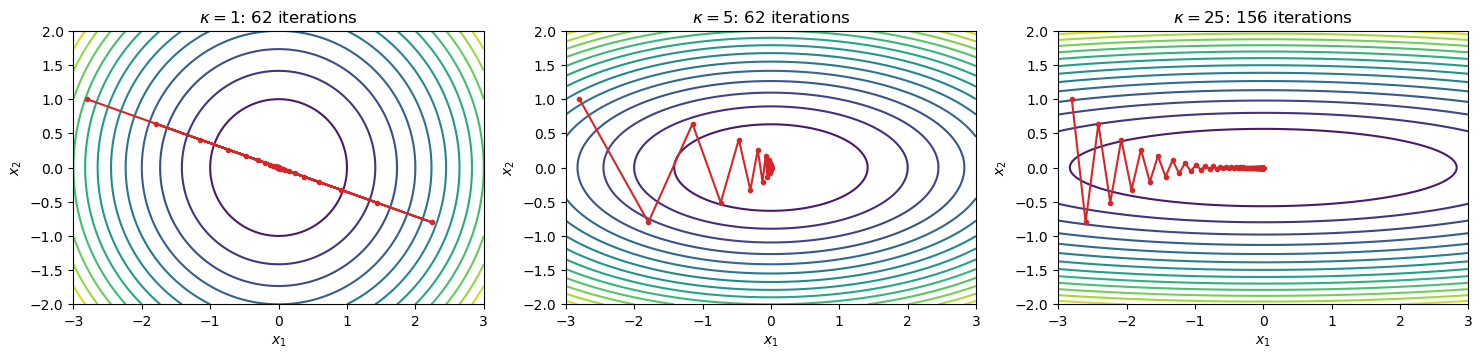

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
xx1, xx2 = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-2, 2, 300))

for ax, lam in zip(axes, [1, 5, 25]):
    A = np.diag([1.0, lam])
    f = lambda x: 0.5 * x @ A @ x
    grad_f = lambda x: A @ x

    x_hist, f_hist, grad_norm = gradient_descent(f, grad_f, np.array([-2.8, 1.0]),
                                                 alpha=1.8 / lam, maxit=1000)

    ax.contour(xx1, xx2, 0.5 * (xx1**2 + lam * xx2**2), levels=15, cmap="viridis")
    ax.plot(x_hist[:, 0], x_hist[:, 1], 'o-', color="tab:red", ms=3)
    ax.set_title(rf"$\kappa = {lam}$: {len(x_hist) - 1} iterations")
    ax.set_aspect("equal")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
plt.show()

In [5]:
def f(x):
    return 100 * (x[1] - x[0]**2)**2 + (1 - x[0])**2

def grad_f(x):
    return np.array([-400 * x[0] * (x[1] - x[0]**2) - 2 * (1 - x[0]),
                     200 * (x[1] - x[0]**2)])

x0 = np.array([-1.5, 2.0])
x_const, f_const, g_const = gradient_descent(f, grad_f, x0, alpha=1e-3, maxit=20000)
x_back, f_back, g_back = gradient_descent(f, grad_f, x0, alpha="backtracking", maxit=20000)

print(f"Constant step: x = {x_const[-1]}, iterations = {len(x_const) - 1}")
print(f"Backtracking:  x = {x_back[-1]}, iterations = {len(x_back) - 1}")

Constant step: x = [0.99888354 0.99776385], iterations = 15403
Backtracking:  x = [1.00039244 1.00078739], iterations = 10012


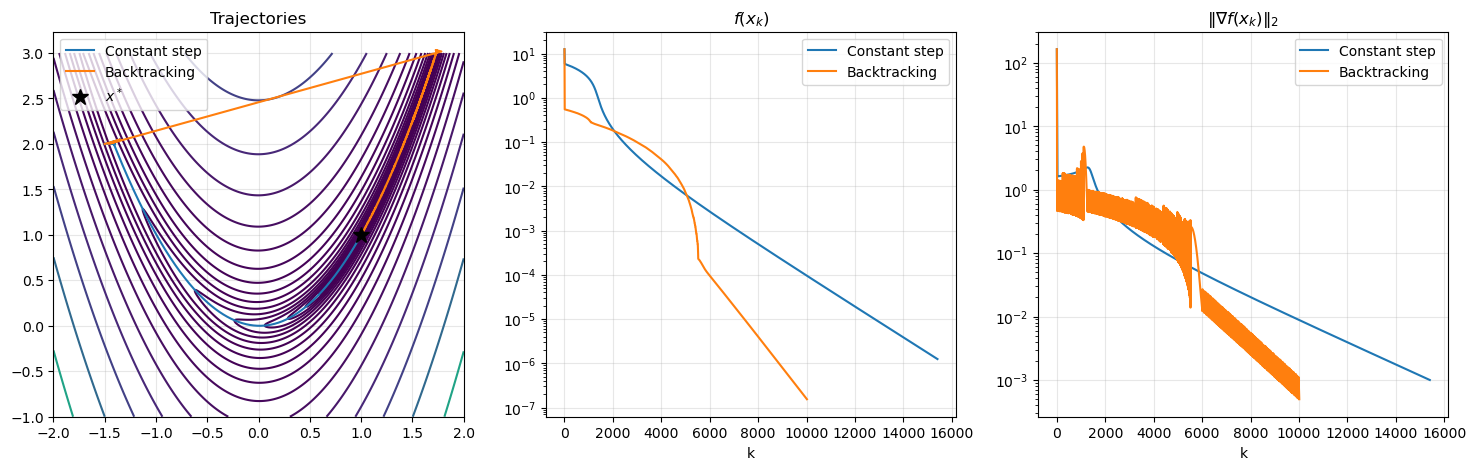

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Trajectories
xx1, xx2 = np.meshgrid(np.linspace(-2, 2, 400), np.linspace(-1, 3, 400))
axes[0].contour(xx1, xx2, 100 * (xx2 - xx1**2)**2 + (1 - xx1)**2,
                levels=np.logspace(-1, 3.5, 20), cmap="viridis")
axes[0].plot(x_const[:, 0], x_const[:, 1], '-', label="Constant step")
axes[0].plot(x_back[:, 0], x_back[:, 1], '-', label="Backtracking")
axes[0].plot(1, 1, 'k*', ms=12, label="$x^*$")
axes[0].set_title("Trajectories")
axes[0].legend()

# Objective function and gradient norm
axes[1].semilogy(f_const, label="Constant step")
axes[1].semilogy(f_back, label="Backtracking")
axes[1].set_title("$f(x_k)$")
axes[1].set_xlabel("k")
axes[1].legend()

axes[2].semilogy(g_const, label="Constant step")
axes[2].semilogy(g_back, label="Backtracking")
axes[2].set_title(r"$\|\nabla f(x_k)\|_2$")
axes[2].set_xlabel("k")
axes[2].legend()

for ax in axes:
    ax.grid(alpha=0.3)
plt.show()

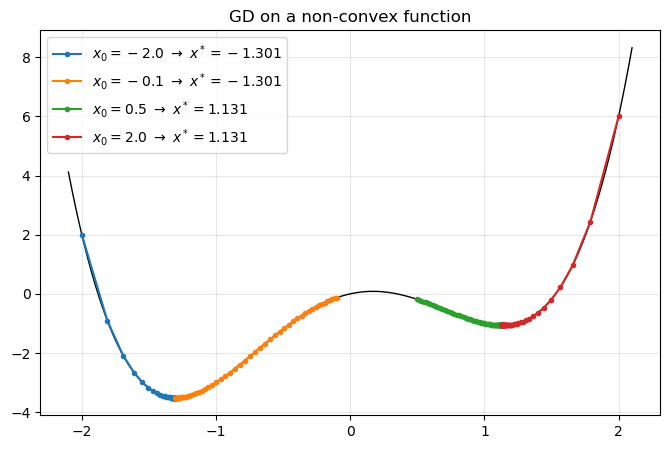

In [7]:
f = lambda x: x**4 - 3 * x**2 + x
grad_f = lambda x: 4 * x**3 - 6 * x + 1

xx = np.linspace(-2.1, 2.1, 300)
plt.figure(figsize=(8, 5))
plt.plot(xx, f(xx), 'k', lw=1)
for x0 in [-2.0, -0.1, 0.5, 2.0]:
    x_hist, f_hist, _ = gradient_descent(f, grad_f, np.array([x0]), alpha=0.01)
    plt.plot(x_hist[:, 0], f_hist, 'o-', ms=3, label=f"$x_0 = {x0}$ $\\to$ $x^* = {x_hist[-1, 0]:.3f}$")
plt.legend()
plt.grid(alpha=0.3)
plt.title("GD on a non-convex function")
plt.show()

In [8]:
# ---- Code from the previous chapter ----
def relu(z):
    return np.maximum(0, z)

def relu_prime(z):
    return (z > 0).astype(float)

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def init_params(sizes, seed=0):
    rng = np.random.default_rng(seed)
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        W = rng.normal(0, np.sqrt(2 / n_in), (n_out, n_in))
        b = np.zeros(n_out)
        params.append([W, b])
    return params

def forward(params, X):
    H = X
    cache = [(None, X)]
    for l, (W, b) in enumerate(params):
        Z = H @ W.T + b
        H = softmax(Z) if l == len(params) - 1 else relu(Z)
        cache.append((Z, H))
    return H, cache

def cross_entropy(Y_hat, Y):
    return -np.mean(np.sum(Y * np.log(Y_hat + 1e-12), axis=1))

def backward(params, cache, Y):
    N = Y.shape[0]
    grads = [None] * len(params)
    Delta = (cache[-1][1] - Y) / N
    for l in reversed(range(len(params))):
        W, b = params[l]
        H_prev = cache[l][1]
        grads[l] = [Delta.T @ H_prev, Delta.sum(axis=0)]
        if l > 0:
            Delta = (Delta @ W) * relu_prime(cache[l][0])
    return grads

# ---- The triangle dataset ----
np.random.seed(0)
N = 1000
X = np.random.uniform(-1.5, 1.5, (N, 2))

def inside_triangle(X):
    x1, x2 = X[:, 0], X[:, 1]
    return ((x2 + 0.7 >= 0) & (1.7 * x1 - x2 + 1 >= 0) & (-1.7 * x1 - x2 + 1 >= 0)).astype(int)

y = inside_triangle(X)
Y = np.eye(2)[y]

In [9]:
def accuracy(Y_hat, y):
    return np.mean(Y_hat.argmax(axis=1) == y)

def train_gd(params, X, Y, y, alpha=0.1, maxit=1000):
    loss_hist, acc_hist = [], []
    for k in range(maxit):
        # Forward and backward pass on the WHOLE dataset
        Y_hat, cache = forward(params, X)
        grads = backward(params, cache, Y)

        # GD update for each parameter
        for (W, b), (dW, db) in zip(params, grads):
            W -= alpha * dW
            b -= alpha * db

        loss_hist.append(cross_entropy(Y_hat, Y))
        acc_hist.append(accuracy(Y_hat, y))
    return params, np.array(loss_hist), np.array(acc_hist)

alpha = 0.01: final loss = 0.1843, final accuracy = 92.70% (time: 0.47s)


alpha = 0.1: final loss = 0.0262, final accuracy = 99.80% (time: 0.45s)


alpha = 0.5: final loss = 0.0067, final accuracy = 100.00% (time: 0.45s)


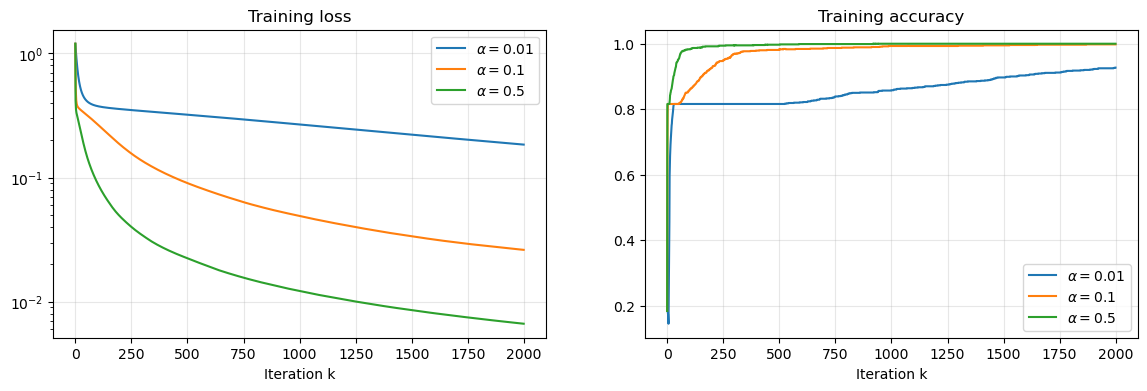

In [10]:
import time

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for alpha in [0.01, 0.1, 0.5]:
    params = init_params([2, 16, 16, 2], seed=0)
    start = time.time()
    params, loss_hist, acc_hist = train_gd(params, X, Y, y, alpha=alpha, maxit=2000)
    print(f"alpha = {alpha}: final loss = {loss_hist[-1]:.4f}, final accuracy = {acc_hist[-1]*100:.2f}%"
          f" (time: {time.time() - start:.2f}s)")

    axes[0].semilogy(loss_hist, label=rf"$\alpha = {alpha}$")
    axes[1].plot(acc_hist, label=rf"$\alpha = {alpha}$")

axes[0].set_title("Training loss")
axes[1].set_title("Training accuracy")
for ax in axes:
    ax.set_xlabel("Iteration k")
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()

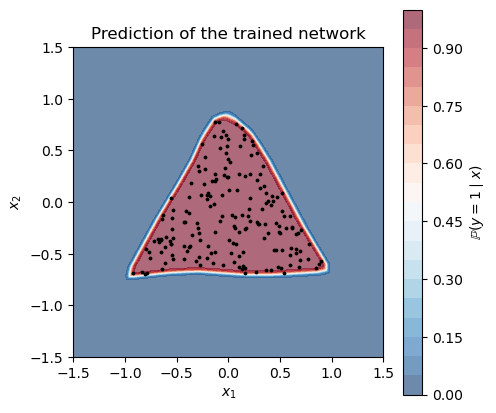

In [11]:
xx1, xx2 = np.meshgrid(np.linspace(-1.5, 1.5, 300), np.linspace(-1.5, 1.5, 300))
grid = np.stack([xx1.ravel(), xx2.ravel()], axis=1)
P_grid, _ = forward(params, grid)

plt.figure(figsize=(5, 5))
plt.contourf(xx1, xx2, P_grid[:, 1].reshape(xx1.shape), levels=20, cmap="RdBu_r", alpha=0.6)
plt.colorbar(label=r"$\mathbb{P}(y = 1 \mid x)$")
plt.scatter(X[y == 1, 0], X[y == 1, 1], s=3, c="k")
plt.title("Prediction of the trained network")
plt.gca().set_aspect("equal")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.show()